In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("../dataset/Telco-Customer-Churn-Cleaned.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


/tmp/ipykernel_606826/3612250191.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [3]:
for feature in categorical_features:

    print("\nFeature:", feature)
    print(df[feature].unique())


Feature: gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Feature: Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Feature: Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Feature: PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Feature: MultipleLines
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

Feature: InternetService
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Feature: OnlineSecurity
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Feature: OnlineBackup
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

Feature: DeviceProtection
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Feature: TechSupport
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Feature: StreamingTV
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dty

In [6]:
binary_features = [
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling"
]

binary_mapping = {
    "Yes": 1,
    "No": 0
}

for feature in binary_features:
    df[feature] = df[feature].map(binary_mapping)

print(df[binary_features].head())

   Partner  Dependents  PhoneService  PaperlessBilling
0        1           0             0                 1
1        0           0             1                 0
2        0           0             1                 1
3        0           0             0                 0
4        0           0             1                 1


In [7]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df["Churn"].value_counts())

Churn
0    5164
1    1857
Name: count, dtype: int64


In [8]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nUpdated dataset:")
df.head()

Dataset shape: (7021, 20)

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Updated dataset:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,Male,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,Male,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,Male,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [9]:
print(df.iloc[4].to_dict())

{'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 0, 'Dependents': 0, 'tenure': 2, 'PhoneService': 1, 'MultipleLines': 'No', 'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 1, 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 70.7, 'TotalCharges': 151.65, 'Churn': 1}


In [12]:
# Identify remaining categorical columns
categorical_features = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Categorical columns to encode:")
print(categorical_features)

print("\nNumber of categorical columns:",
      len(categorical_features))

Categorical columns to encode:
['gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

Number of categorical columns: 11


In [13]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)

df_encoded.head()

Original dataset shape: (7021, 20)
Encoded dataset shape: (7021, 31)


,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,gender_Male,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,1,29.85,29.85,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,0,0,34,1,0,56.95,1889.50,0,1,...,0,0,0,0,0,1,0,0,0,1
2,0,0,0,2,1,1,53.85,108.15,1,1,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,45,0,0,42.30,1840.75,0,1,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,2,1,1,70.70,151.65,1,0,...,0,0,0,0,0,0,0,0,1,0


In [14]:
print("Remaining categorical columns:")

print(
    df_encoded.select_dtypes(
        include=["object", "str", "category"]
    ).columns.tolist()
)

print("\nTotal columns:", df_encoded.shape[1])

print("\nMissing values:", df_encoded.isnull().sum().sum())

print("\nDuplicate rows:", df_encoded.duplicated().sum())

Remaining categorical columns:
[]

Total columns: 31

Missing values: 0

Duplicate rows: 0


In [15]:
df_encoded["TenureGroup"] = pd.cut(
    df_encoded["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Medium", "Long-term", "Loyal"]
)

print(df_encoded[["tenure", "TenureGroup"]].head(10))

print("\nTenure Group Distribution:")
print(df_encoded["TenureGroup"].value_counts())

   tenure TenureGroup
0       1         New
1      34   Long-term
2       2         New
3      45   Long-term
4       2         New
5       8         New
6      22      Medium
7      10         New
8      28   Long-term
9      62       Loyal

Tenure Group Distribution:
TenureGroup
Loyal        2239
New          2164
Long-term    1594
Medium       1024
Name: count, dtype: int64


In [16]:
# Create Average Monthly Spend

df_encoded["AverageMonthlySpend"] = np.where(
    df_encoded["tenure"] > 0,
    df_encoded["TotalCharges"] / df_encoded["tenure"],
    df_encoded["MonthlyCharges"]
)

print(
    df_encoded[
        ["tenure", "MonthlyCharges", "TotalCharges",
         "AverageMonthlySpend"]
    ].head(10)
)

   tenure  MonthlyCharges  TotalCharges  AverageMonthlySpend
0       1           29.85         29.85            29.850000
1      34           56.95       1889.50            55.573529
2       2           53.85        108.15            54.075000
3      45           42.30       1840.75            40.905556
4       2           70.70        151.65            75.825000
5       8           99.65        820.50           102.562500
6      22           89.10       1949.40            88.609091
7      10           29.75        301.90            30.190000
8      28          104.80       3046.05           108.787500
9      62           56.15       3487.95            56.257258


In [17]:
print(df_encoded["AverageMonthlySpend"].describe())

count    7021.000000
mean       64.853112
std        30.169128
min        13.775000
25%        36.316667
50%        70.450000
75%        90.197183
max       121.400000
Name: AverageMonthlySpend, dtype: float64


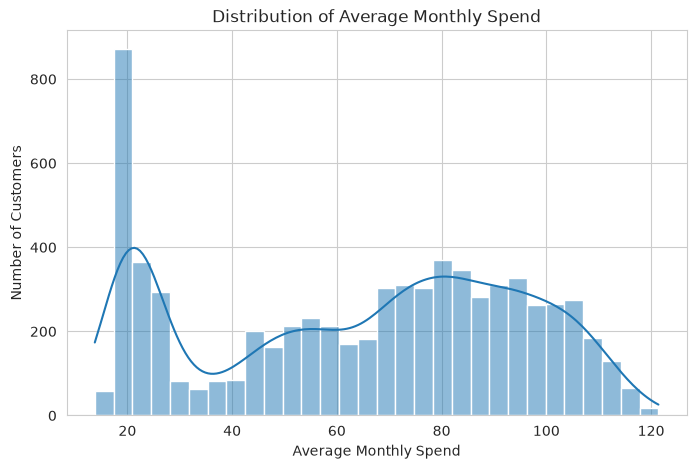

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df_encoded["AverageMonthlySpend"],
    bins=30,
    kde=True
)

plt.title("Distribution of Average Monthly Spend")
plt.xlabel("Average Monthly Spend")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
print(
    df_encoded.groupby("Churn")["AverageMonthlySpend"].mean()
)

Churn
0    61.349493
1    74.596077
Name: AverageMonthlySpend, dtype: float64


In [20]:
# Create indicators for each subscribed service

service_features = pd.DataFrame(index=df.index)

service_features["PhoneService"] = df["PhoneService"]

service_features["MultipleLines"] = (
    df["MultipleLines"] == "Yes"
).astype(int)

service_features["InternetService"] = (
    df["InternetService"] != "No"
).astype(int)

other_services = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for feature in other_services:
    service_features[feature] = (
        df[feature] == "Yes"
    ).astype(int)

# Calculate total services
df_encoded["TotalServices"] = service_features.sum(axis=1)

print(df_encoded[["TotalServices"]].head(10))

   TotalServices
0              2
1              4
2              4
3              4
4              2
5              6
6              5
7              2
8              7
9              4


In [21]:
print(df_encoded["TotalServices"].describe())

count    7021.000000
mean        4.154964
std         2.310924
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max         9.000000
Name: TotalServices, dtype: float64


In [22]:
print(
    df_encoded.groupby("Churn")["TotalServices"].mean()
)

Churn
0    4.179318
1    4.087237
Name: TotalServices, dtype: float64


In [23]:
engineered_features = [
    "TenureGroup",
    "AverageMonthlySpend",
    "TotalServices"
]

print(df_encoded[engineered_features].head(10))

print("\nMissing values:")
print(df_encoded[engineered_features].isnull().sum())

print("\nUpdated dataset shape:")
print(df_encoded.shape)

  TenureGroup  AverageMonthlySpend  TotalServices
0         New            29.850000              2
1   Long-term            55.573529              4
2         New            54.075000              4
3   Long-term            40.905556              4
4         New            75.825000              2
5         New           102.562500              6
6      Medium            88.609091              5
7         New            30.190000              2
8   Long-term           108.787500              7
9       Loyal            56.257258              4

Missing values:
TenureGroup            0
AverageMonthlySpend    0
TotalServices          0
dtype: int64

Updated dataset shape:
(7021, 34)


In [24]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "AverageMonthlySpend",
    "TotalServices"
]

print(df_encoded[numerical_features].describe())

            tenure  MonthlyCharges  TotalCharges  AverageMonthlySpend  \
count  7021.000000     7021.000000   7021.000000          7021.000000   
mean     32.469449       64.851894   2286.765026            64.853112   
std      24.534965       30.069001   2266.855057            30.169128   
min       0.000000       18.250000      0.000000            13.775000   
25%       9.000000       35.750000    403.350000            36.316667   
50%      29.000000       70.400000   1400.550000            70.450000   
75%      55.000000       89.900000   3801.700000            90.197183   
max      72.000000      118.750000   8684.800000           121.400000   

       TotalServices  
count    7021.000000  
mean        4.154964  
std         2.310924  
min         1.000000  
25%         2.000000  
50%         4.000000  
75%         6.000000  
max         9.000000  


In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
scaler = StandardScaler()

df_scaled = df_encoded.copy()

df_scaled[numerical_features] = scaler.fit_transform(
    df_scaled[numerical_features]
)

In [27]:
print("Before Scaling:")
print(df_encoded[numerical_features].head())

print("\nAfter Standard Scaling:")
print(df_scaled[numerical_features].head())

Before Scaling:
   tenure  MonthlyCharges  TotalCharges  AverageMonthlySpend  TotalServices
0       1           29.85         29.85            29.850000              2
1      34           56.95       1889.50            55.573529              4
2       2           53.85        108.15            54.075000              4
3      45           42.30       1840.75            40.905556              4
4       2           70.70        151.65            75.825000              2

After Standard Scaling:
     tenure  MonthlyCharges  TotalCharges  AverageMonthlySpend  TotalServices
0 -1.282728       -1.164135     -0.995686            -1.160312      -0.932578
1  0.062387       -0.262811     -0.175262            -0.307607      -0.067062
2 -1.241967       -0.365914     -0.961142            -0.357282      -0.067062
3  0.510759       -0.750058     -0.196769            -0.793833      -0.067062
4 -1.241967        0.194503     -0.941951             0.363705      -0.932578


In [28]:
print("Mean after scaling:")
print(df_scaled[numerical_features].mean())

print("\nStandard deviation after scaling:")
print(df_scaled[numerical_features].std())

Mean after scaling:
tenure                 8.855219e-17
MonthlyCharges        -2.105012e-16
TotalCharges          -4.250505e-17
AverageMonthlySpend   -7.488985e-17
TotalServices          1.072746e-16
dtype: float64

Standard deviation after scaling:
tenure                 1.000071
MonthlyCharges         1.000071
TotalCharges           1.000071
AverageMonthlySpend    1.000071
TotalServices          1.000071
dtype: float64


In [29]:
from sklearn.preprocessing import MinMaxScaler

In [30]:
minmax_scaler = MinMaxScaler()

df_minmax = df_encoded.copy()

df_minmax[numerical_features] = minmax_scaler.fit_transform(
    df_minmax[numerical_features]
)

In [31]:
print("Before MinMax Scaling:")
print(df_encoded[numerical_features].head())

print("\nAfter MinMax Scaling:")
print(df_minmax[numerical_features].head())

Before MinMax Scaling:
   tenure  MonthlyCharges  TotalCharges  AverageMonthlySpend  TotalServices
0       1           29.85         29.85            29.850000              2
1      34           56.95       1889.50            55.573529              4
2       2           53.85        108.15            54.075000              4
3      45           42.30       1840.75            40.905556              4
4       2           70.70        151.65            75.825000              2

After MinMax Scaling:
     tenure  MonthlyCharges  TotalCharges  AverageMonthlySpend  TotalServices
0  0.013889        0.115423      0.003437             0.149361          0.125
1  0.472222        0.385075      0.217564             0.388372          0.375
2  0.027778        0.354229      0.012453             0.374448          0.375
3  0.625000        0.239303      0.211951             0.252084          0.375
4  0.027778        0.521891      0.017462             0.576539          0.125


In [32]:
print("Minimum values after MinMax Scaling:")
print(df_minmax[numerical_features].min())

print("\nMaximum values after MinMax Scaling:")
print(df_minmax[numerical_features].max())

Minimum values after MinMax Scaling:
tenure                 0.0
MonthlyCharges         0.0
TotalCharges           0.0
AverageMonthlySpend    0.0
TotalServices          0.0
dtype: float64

Maximum values after MinMax Scaling:
tenure                 1.0
MonthlyCharges         1.0
TotalCharges           1.0
AverageMonthlySpend    1.0
TotalServices          1.0
dtype: float64


In [33]:
# Select numerical columns
correlation_data = df_encoded.select_dtypes(
    include=["number"]
)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
correlation_matrix.head()

Correlation Matrix:


,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,gender_Male,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,AverageMonthlySpend,TotalServices
SeniorCitizen,1.000000,0.015553,-0.212115,0.015349,0.008909,0.156196,0.219434,0.102243,0.151619,-0.001125,...,0.104765,-0.181940,0.119584,-0.046823,-0.117694,-0.024683,0.171347,-0.152338,0.217172,0.117151
Partner,0.015553,1.000000,0.451659,0.377346,0.018728,-0.015776,0.094301,0.315452,-0.149135,-0.001014,...,0.122572,0.003720,0.115284,0.081379,0.246870,0.080592,-0.084500,-0.092031,0.093616,0.192748
Dependents,-0.212115,0.451659,1.000000,0.157603,-0.001092,-0.112220,-0.116191,0.060182,-0.163459,0.011081,...,-0.018207,0.142531,-0.041441,0.067388,0.203697,0.059256,-0.151232,0.061789,-0.116316,-0.008735
tenure,0.015349,0.377346,0.157603,1.000000,0.009786,0.005053,0.245251,0.825595,-0.351508,0.006185,...,0.277575,-0.035206,0.283932,0.201110,0.557984,0.231597,-0.209731,-0.230606,0.244591,0.471292
PhoneService,0.008909,0.018728,-0.001092,0.009786,1.000000,0.016824,0.248984,0.114424,0.011323,-0.006769,...,-0.021788,0.171839,-0.032179,-0.002264,0.004099,-0.007187,0.003204,-0.004555,0.248846,0.084229


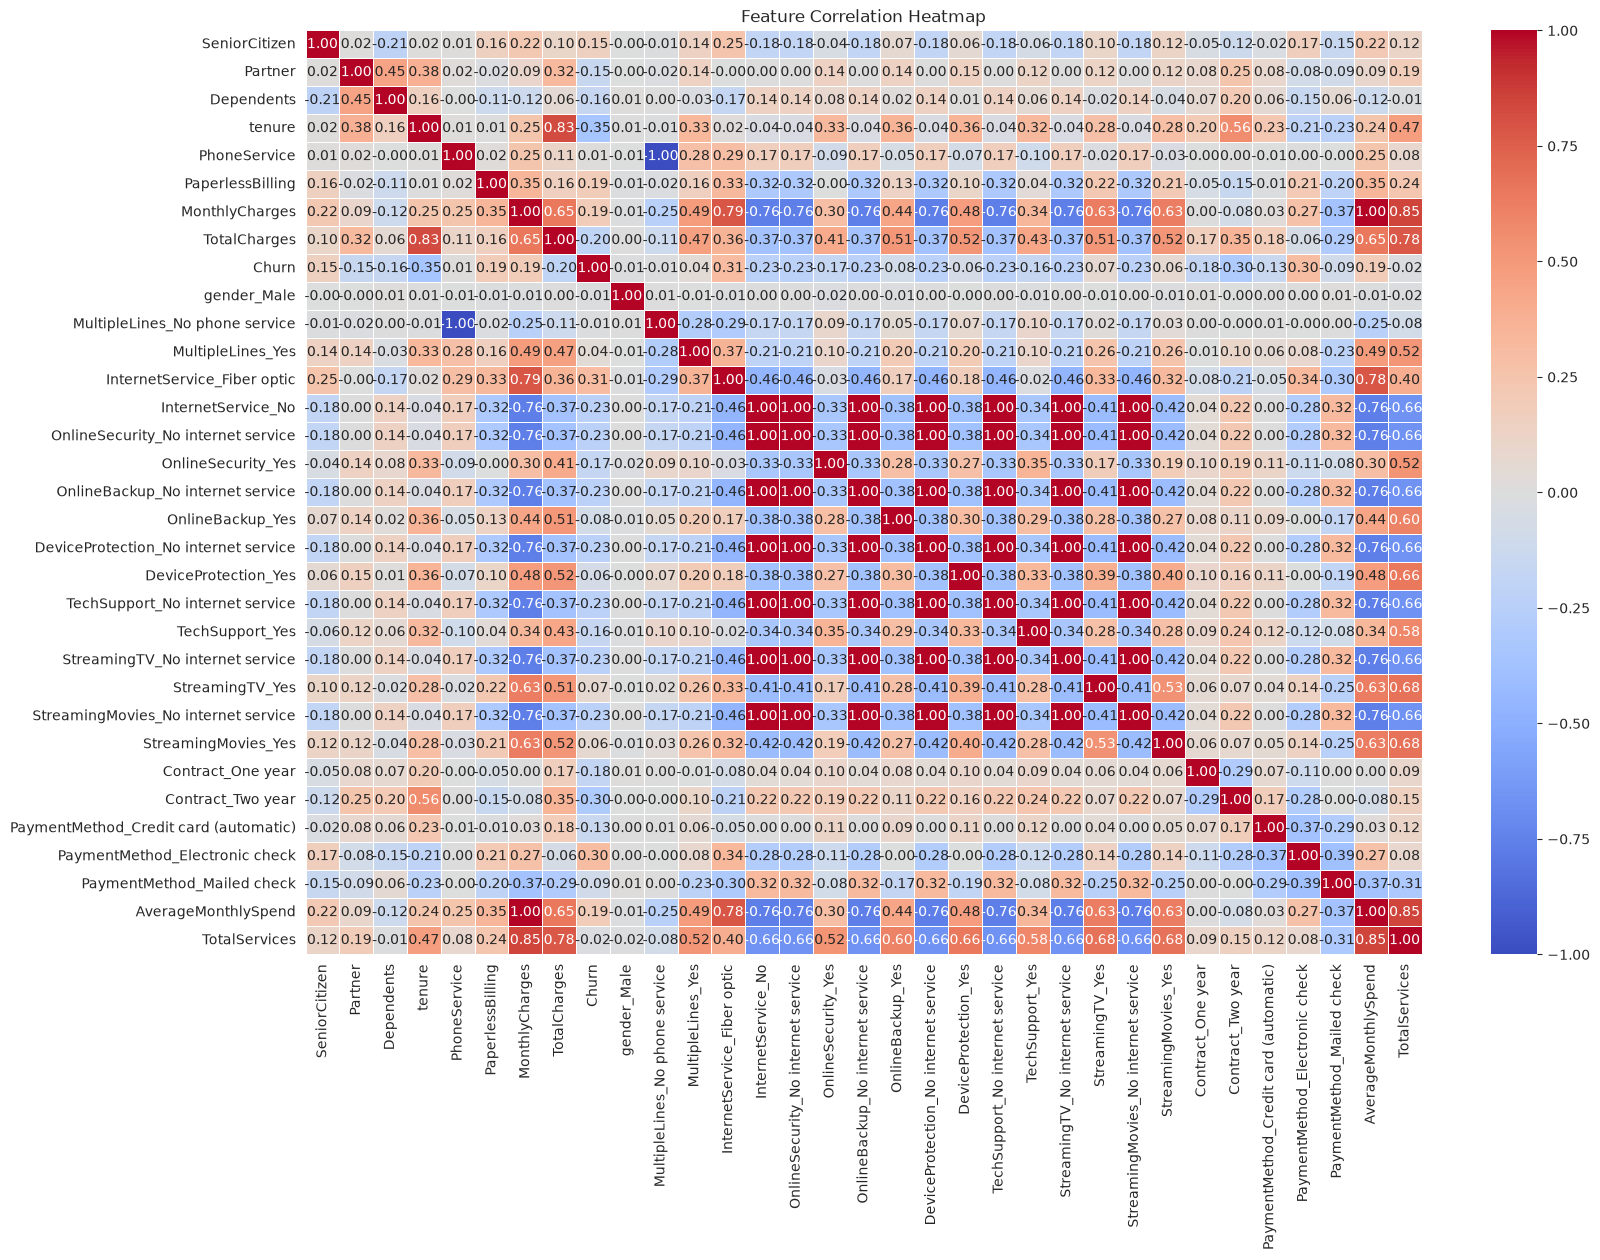

In [34]:
plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [35]:
churn_correlation = correlation_matrix["Churn"].sort_values(
    ascending=False
)

print("Correlation of features with Churn:")
print(churn_correlation)

Correlation of features with Churn:
Churn                                    1.000000
InternetService_Fiber optic              0.308170
PaymentMethod_Electronic check           0.301544
MonthlyCharges                           0.194508
AverageMonthlySpend                      0.193674
PaperlessBilling                         0.190891
SeniorCitizen                            0.151619
StreamingTV_Yes                          0.065032
StreamingMovies_Yes                      0.063192
MultipleLines_Yes                        0.041958
PhoneService                             0.011323
gender_Male                             -0.008763
MultipleLines_No phone service          -0.011323
TotalServices                           -0.017576
DeviceProtection_Yes                    -0.064944
OnlineBackup_Yes                        -0.081092
PaymentMethod_Mailed check              -0.092562
PaymentMethod_Credit card (automatic)   -0.133666
Partner                                 -0.149135
Dependents    

In [36]:
# Remove target from input feature correlations
feature_corr = correlation_matrix.drop(
    columns=["Churn"],
    index=["Churn"]
)

# Get upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

# Find pairs with absolute correlation above 0.80
high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() > 0.80
].sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

print("Highly correlated feature pairs:")
print(high_corr_pairs)

Highly correlated feature pairs:
                                Feature 1  \
397                    InternetService_No   
399                    InternetService_No   
405                    InternetService_No   
407                    InternetService_No   
403                    InternetService_No   
401                    InternetService_No   
437    OnlineSecurity_No internet service   
435    OnlineSecurity_No internet service   
433    OnlineSecurity_No internet service   
431    OnlineSecurity_No internet service   
503      OnlineBackup_No internet service   
563  DeviceProtection_No internet service   
565  DeviceProtection_No internet service   
567  DeviceProtection_No internet service   
439    OnlineSecurity_No internet service   
497      OnlineBackup_No internet service   
499      OnlineBackup_No internet service   
501      OnlineBackup_No internet service   
629       TechSupport_No internet service   
631       TechSupport_No internet service   
695       StreamingTV_

In [37]:
# Display all highly correlated feature pairs

pd.set_option("display.max_rows", None)

print(
    high_corr_pairs.to_string(index=False)
)

pd.reset_option("display.max_rows")

                           Feature 1                            Feature 2  Correlation
                  InternetService_No   OnlineSecurity_No internet service     1.000000
                  InternetService_No     OnlineBackup_No internet service     1.000000
                  InternetService_No      StreamingTV_No internet service     1.000000
                  InternetService_No  StreamingMovies_No internet service     1.000000
                  InternetService_No      TechSupport_No internet service     1.000000
                  InternetService_No DeviceProtection_No internet service     1.000000
  OnlineSecurity_No internet service      StreamingTV_No internet service     1.000000
  OnlineSecurity_No internet service      TechSupport_No internet service     1.000000
  OnlineSecurity_No internet service DeviceProtection_No internet service     1.000000
  OnlineSecurity_No internet service     OnlineBackup_No internet service     1.000000
    OnlineBackup_No internet service  Strea

In [38]:
print("Top 10 positive correlations with Churn:")
print(
    churn_correlation.drop("Churn")
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 negative correlations with Churn:")
print(
    churn_correlation.drop("Churn")
    .sort_values(ascending=True)
    .head(10)
)

Top 10 positive correlations with Churn:
InternetService_Fiber optic       0.308170
PaymentMethod_Electronic check    0.301544
MonthlyCharges                    0.194508
AverageMonthlySpend               0.193674
PaperlessBilling                  0.190891
SeniorCitizen                     0.151619
StreamingTV_Yes                   0.065032
StreamingMovies_Yes               0.063192
MultipleLines_Yes                 0.041958
PhoneService                      0.011323
Name: Churn, dtype: float64

Top 10 negative correlations with Churn:
tenure                                 -0.351508
Contract_Two year                      -0.302076
TechSupport_No internet service        -0.228533
InternetService_No                     -0.228533
StreamingTV_No internet service        -0.228533
OnlineSecurity_No internet service     -0.228533
StreamingMovies_No internet service    -0.228533
OnlineBackup_No internet service       -0.228533
DeviceProtection_No internet service   -0.228533
TotalCharges      

In [39]:
# Create final dataset for initial model preparation

df_final = df_encoded.drop(
    columns=["AverageMonthlySpend"]
).copy()

print("Final dataset shape:", df_final.shape)

print("\nMissing values:")
print(df_final.isnull().sum().sum())

print("\nData types:")
print(df_final.dtypes.value_counts())

print("\nFinal columns:")
print(df_final.columns.tolist())

Final dataset shape: (7021, 33)

Missing values:
0

Data types:
int64       30
float64      2
category     1
Name: count, dtype: int64

Final columns:
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender_Male', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'TenureGroup', 'TotalServices']


In [40]:
print("Target distribution:")
print(df_final["Churn"].value_counts())

print("\nTarget percentage:")
print(
    df_final["Churn"].value_counts(normalize=True) * 100
)

Target distribution:
Churn
0    5164
1    1857
Name: count, dtype: int64

Target percentage:
Churn
0    73.550776
1    26.449224
Name: proportion, dtype: float64


In [41]:
# Convert TenureGroup into one-hot encoded columns

df_final = pd.get_dummies(
    df_final,
    columns=["TenureGroup"],
    drop_first=True,
    dtype=int
)

print("Updated dataset shape:", df_final.shape)

print("\nRemaining non-numeric columns:")
print(
    df_final.select_dtypes(
        exclude=["number"]
    ).columns.tolist()
)

print("\nFinal columns:")
print(df_final.columns.tolist())

Updated dataset shape: (7021, 35)

Remaining non-numeric columns:
[]

Final columns:
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender_Male', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'TotalServices', 'TenureGroup_Medium', 'TenureGroup_Long-term', 'TenureGroup_Loyal']


In [42]:
# Save the final feature-engineered dataset

df_final.to_csv(
    "../dataset/Telco-Customer-Churn-Feature-Engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")
print("Dataset shape:", df_final.shape)

Feature-engineered dataset saved successfully!
Dataset shape: (7021, 35)
